In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

## Writing helper codes from last sub-part (1-b)

In [18]:
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0

    def __repr__(self):
        return(f"Value (data = {self.data})")

    def __add__(self, other):
        out = self.data + other.data
        return Value(out, _children = (self, other), _op = '+')

    def __mul__(self, other):
        out = self.data * other.data
        return Value(out, _children = (self, other), _op = '*')

In [20]:
# a = Value(1)
# a.tanh()

In [21]:
## Let's add grad to our visualization pipeline as well

from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format = 'svg', graph_attr = {'rankdir': 'LR'}) ## LR - Left to Right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))   # The id() function returns a unique id for the specified object.

        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad ), shape = 'record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    # if the nodes are in edges
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot
    
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a * b   ## python will internally call a.__add__(b)
e.label = 'e'

d = e + c
d.label = 'd'

f = Value(-2.0, label = 'f')
L = d * f
L.label = 'L'


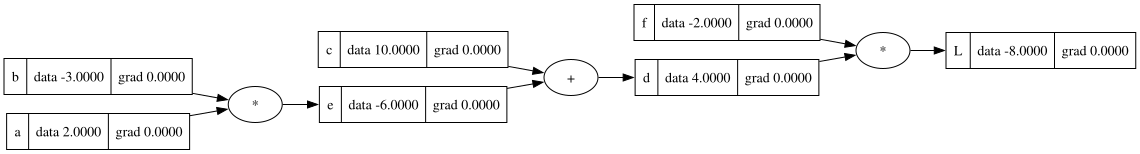

In [22]:
draw_dot(L)

# We are going to back-propogate through a neuron.

![Alt text](images/neuron.png)

### This is a simple mathematical model of a neuron. You have some inputs x0 x1 ..., then you have these synapses that have weights on them, so the w's are weights. 

![Alt text](images/neuron_model.jpeg)

So the synapse interacts with the input to this nueron multiplicatively, so what flows to the cell body of this neuron is:

$$\sum{w_ix_i + b}$$

- The cell body then has a bias (this is sort like the innate trigger happiness of this neuron). So this bias can make it bit more trigger happy or a bit less trigger happy regardless of the input.
- We pass the output through an activation function. The activation function is some sort of a squasing function like a sigmoid or tanh, or something like that.

### We will use a tanh in this example

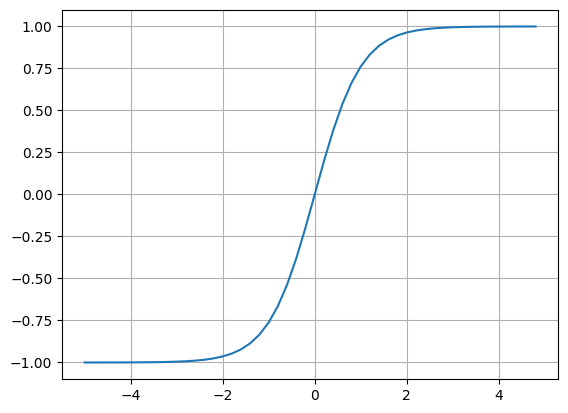

In [23]:
x = np.arange(-5, 5, 0.2)
y = np.arange(-5, 5, 0.2)

y = np.tanh(x)
plt.plot(x, y)
plt.grid()

- So in this case, if the input is 0, we will get exactly zero.
- As you increase the value of x towards positive, the function will only go upto 1 and will plateau out.
- So, if you pass it a very positive input, we will cap it smoothly to 1, and on the negative side, we're gonna cap it smoothly to -1.

## Let's create a neuron logic-


In [24]:
## inputs (2-D nuerons)
x1 = Value(2.0, label = "x1")
x2 = Value(0.0, label = "x2")

# weights
w1 = Value(-3.0, label = "w1")
w2 = Value(1.0, label = "w2")

# bias of the neuron
b = Value(6.7, label = "b")

# calculation of x1w1 + x2w2 + b
x1w1 = x1*w1
x1w1.label = "x1*w1"

x2w2 = x2*w2
x2w2.label = "x2*w2"

x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"

n = x1w1x2w2 + b
n.label = 'n'

o = n.tanh()

AttributeError: 'Value' object has no attribute 'tanh'

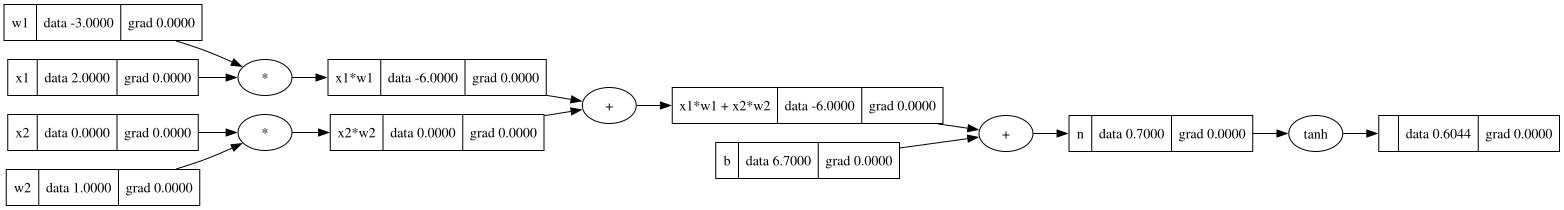

In [25]:
draw_dot(o)

In [26]:
o = n.tanh()

AttributeError: 'Value' object has no attribute 'tanh'

### We cannot directly use the tanh function here. 
We have to create the function inside our Value class.

The reason we have to create a new function is "tanh is an hyperbolic function", and we cannot implement it using our add and mul function. 

## Let's update the Value class

In [27]:
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0

    def __repr__(self):
        return(f"Value (data = {self.data})")

    def __add__(self, other):
        out = self.data + other.data
        return Value(out, _children = (self, other), _op = '+')

    def __mul__(self, other):
        out = self.data * other.data
        return Value(out, _children = (self, other), _op = '*')
    
    # def tanh(self):
    #     out = np.tanh(self.data)
    #     return Value(out, _children = (self, ), _op = 'tanh')

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        return Value(t, _children = (self, ), _op = 'tanh')           

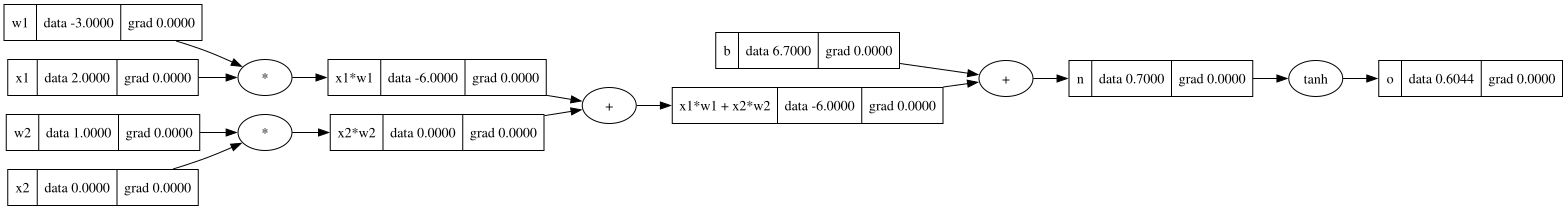

In [29]:
## inputs (2-D nuerons)
x1 = Value(2.0, label = "x1")
x2 = Value(0.0, label = "x2")

# weights
w1 = Value(-3.0, label = "w1")
w2 = Value(1.0, label = "w2")

# bias of the neuron
b = Value(6.7, label = "b")

# calculation of x1w1 + x2w2 + b
x1w1 = x1*w1
x1w1.label = "x1*w1"

x2w2 = x2*w2
x2w2.label = "x2*w2"

x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"

n = x1w1x2w2 + b
n.label = 'n'

o = n.tanh()
o.label = 'o'
draw_dot(o)


So now `tanh` is our micrograd supported node here as an operation, and as long we know derivative of `tanh`, we will be able to back-propogate as well.

## Now, let's see tanh in action:

Currently it is not squashing too much, because the input to it is pretty low. So, let's increase this value by increasing the value of bias to 8.0. Now the n is 2.00, but o is 0.96.

## Backpropogation in Neuron

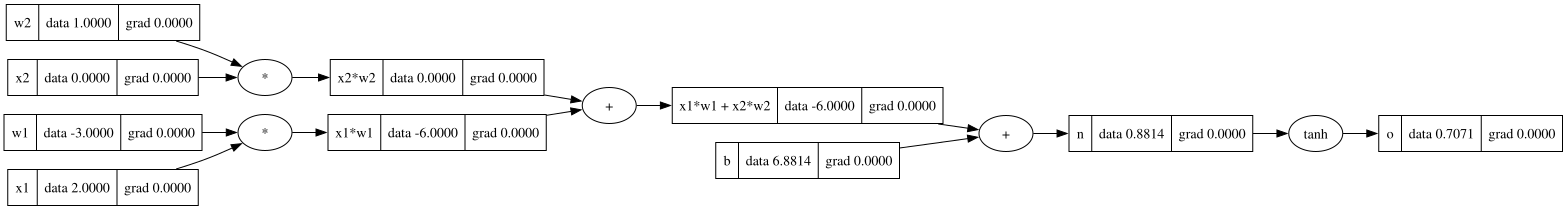

In [30]:
## inputs (2-D nuerons)
x1 = Value(2.0, label = "x1")
x2 = Value(0.0, label = "x2")

# weights
w1 = Value(-3.0, label = "w1")
w2 = Value(1.0, label = "w2")

# bias of the neuron
b = Value(6.8813735870195432, label = "b")

# calculation of x1w1 + x2w2 + b
x1w1 = x1*w1
x1w1.label = "x1*w1"

x2w2 = x2*w2
x2w2.label = "x2*w2"

x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"

n = x1w1x2w2 + b
n.label = 'n'

o = n.tanh()
o.label = 'o'
draw_dot(o)


The reason we changed the bias to 6.88... is because we want to do back-propogation, and we want to see our number coming out nicely (not sure yet, let's see)

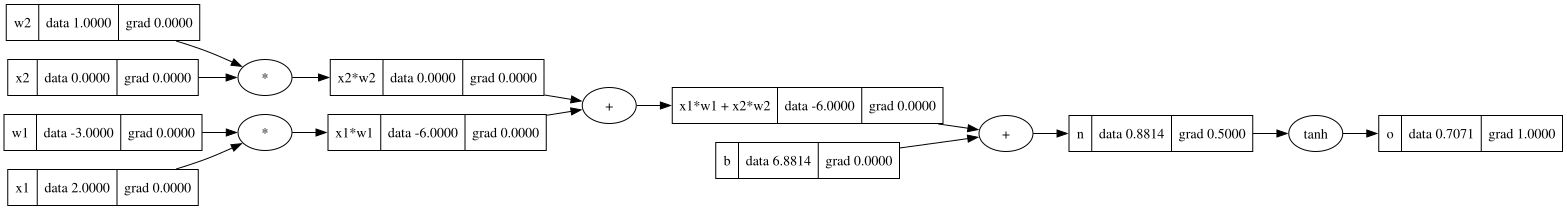

In [34]:
## Let's calculate gradients
o.grad = 1.0

## n.grad, o is tanh(n), the derivative of tanh(x) = 1-tanh(x)^2
## do/dn = 1 - o**2
n.grad = 1 - o.data**2

## Let's plot them
draw_dot(o)

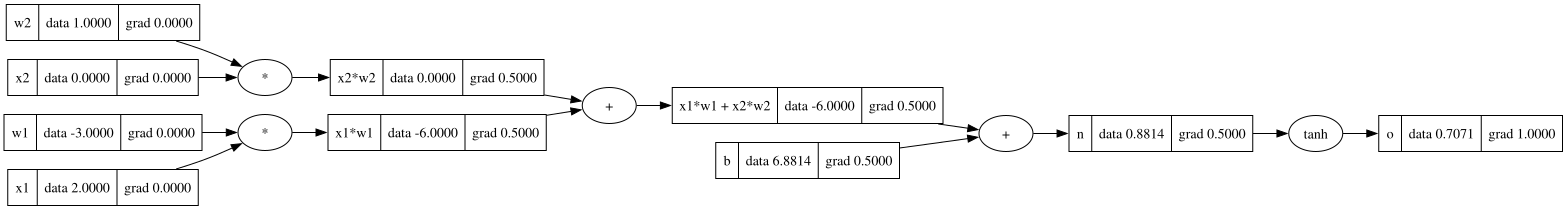

In [36]:
# Because n is formed from additive node, the derivative will be distributed to both the child nodes.
x1w1x2w2.grad = 0.5
b.grad = 0.5

# Similarly, x2w2 and x1w1 will have gradient as x1w1x2w2.grad

x1w1.grad = 0.5
x2w2.grad = 0.5
draw_dot(o)

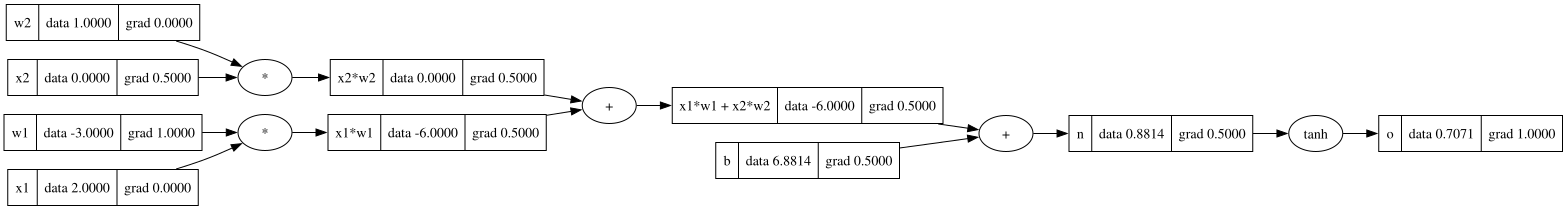

In [37]:
## So for multiplication term, the derivative is the product of the grad of parent node, and the other child node data

x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

x1grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

draw_dot(o)